In [1]:
import sys, os
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

# CLT versus Efron bootstrap

In [2]:
import pandas as pd
from src.eda_and_intervals import step5, step6
display(step5())

,Bank,Mean,Mean_CLT_low,Mean_CLT_high,Wald_z,Wald_p,Annualised Volatility,Normal_theory_low,Normal_theory_high,Delta_method_low,Delta_method_high,Excess Kurtosis
0,DBS,0.000556,0.000128,0.000984,2.546231,0.010889,0.182099,0.177297,0.186901,0.172945,0.191253,5.267616
1,OCBC,0.000361,-0.000020,0.000742,1.856212,0.063423,0.162164,0.157888,0.166440,0.154146,0.170182,5.031124
2,UOB,0.000370,-0.000036,0.000776,1.785535,0.074175,0.172958,0.168397,0.177519,0.164274,0.181643,5.251339


Mean Wald intervals identify whether the daily mean differs materially from zero; the result depends on each bank's sample mean and heavy-tailed volatility.

In [3]:
comparison = step6()
display(comparison.drop(columns=[c for c in comparison if c.startswith("Vol_") == False]))

,Vol_normal_low,Vol_normal_high,Vol_delta_low,Vol_delta_high,Vol_boot_low,Vol_boot_high
0,0.177297,0.186901,0.172945,0.191253,0.173144,0.191348
1,0.157888,0.166440,0.154146,0.170182,0.154278,0.170274
2,0.168397,0.177519,0.164274,0.181643,0.164532,0.181997


Mean CLT and bootstrap intervals agree closely, while the volatility comparison shows why fourth moments and resampling matter under heavy tails.

In [4]:
display(pd.read_csv("outputs/tables/step6_monte_carlo_coverage.csv"))

,Method,Coverage
0,Normal-theory CLT,0.701
1,Delta-method CLT,0.925
2,Efron Bootstrap,0.926


Under simulated Student-t returns with nu=5, Delta and bootstrap intervals are Delta coverage is 92.5%, Efron bootstrap coverage is 92.6%, and Normal-theory coverage is 70.1%.

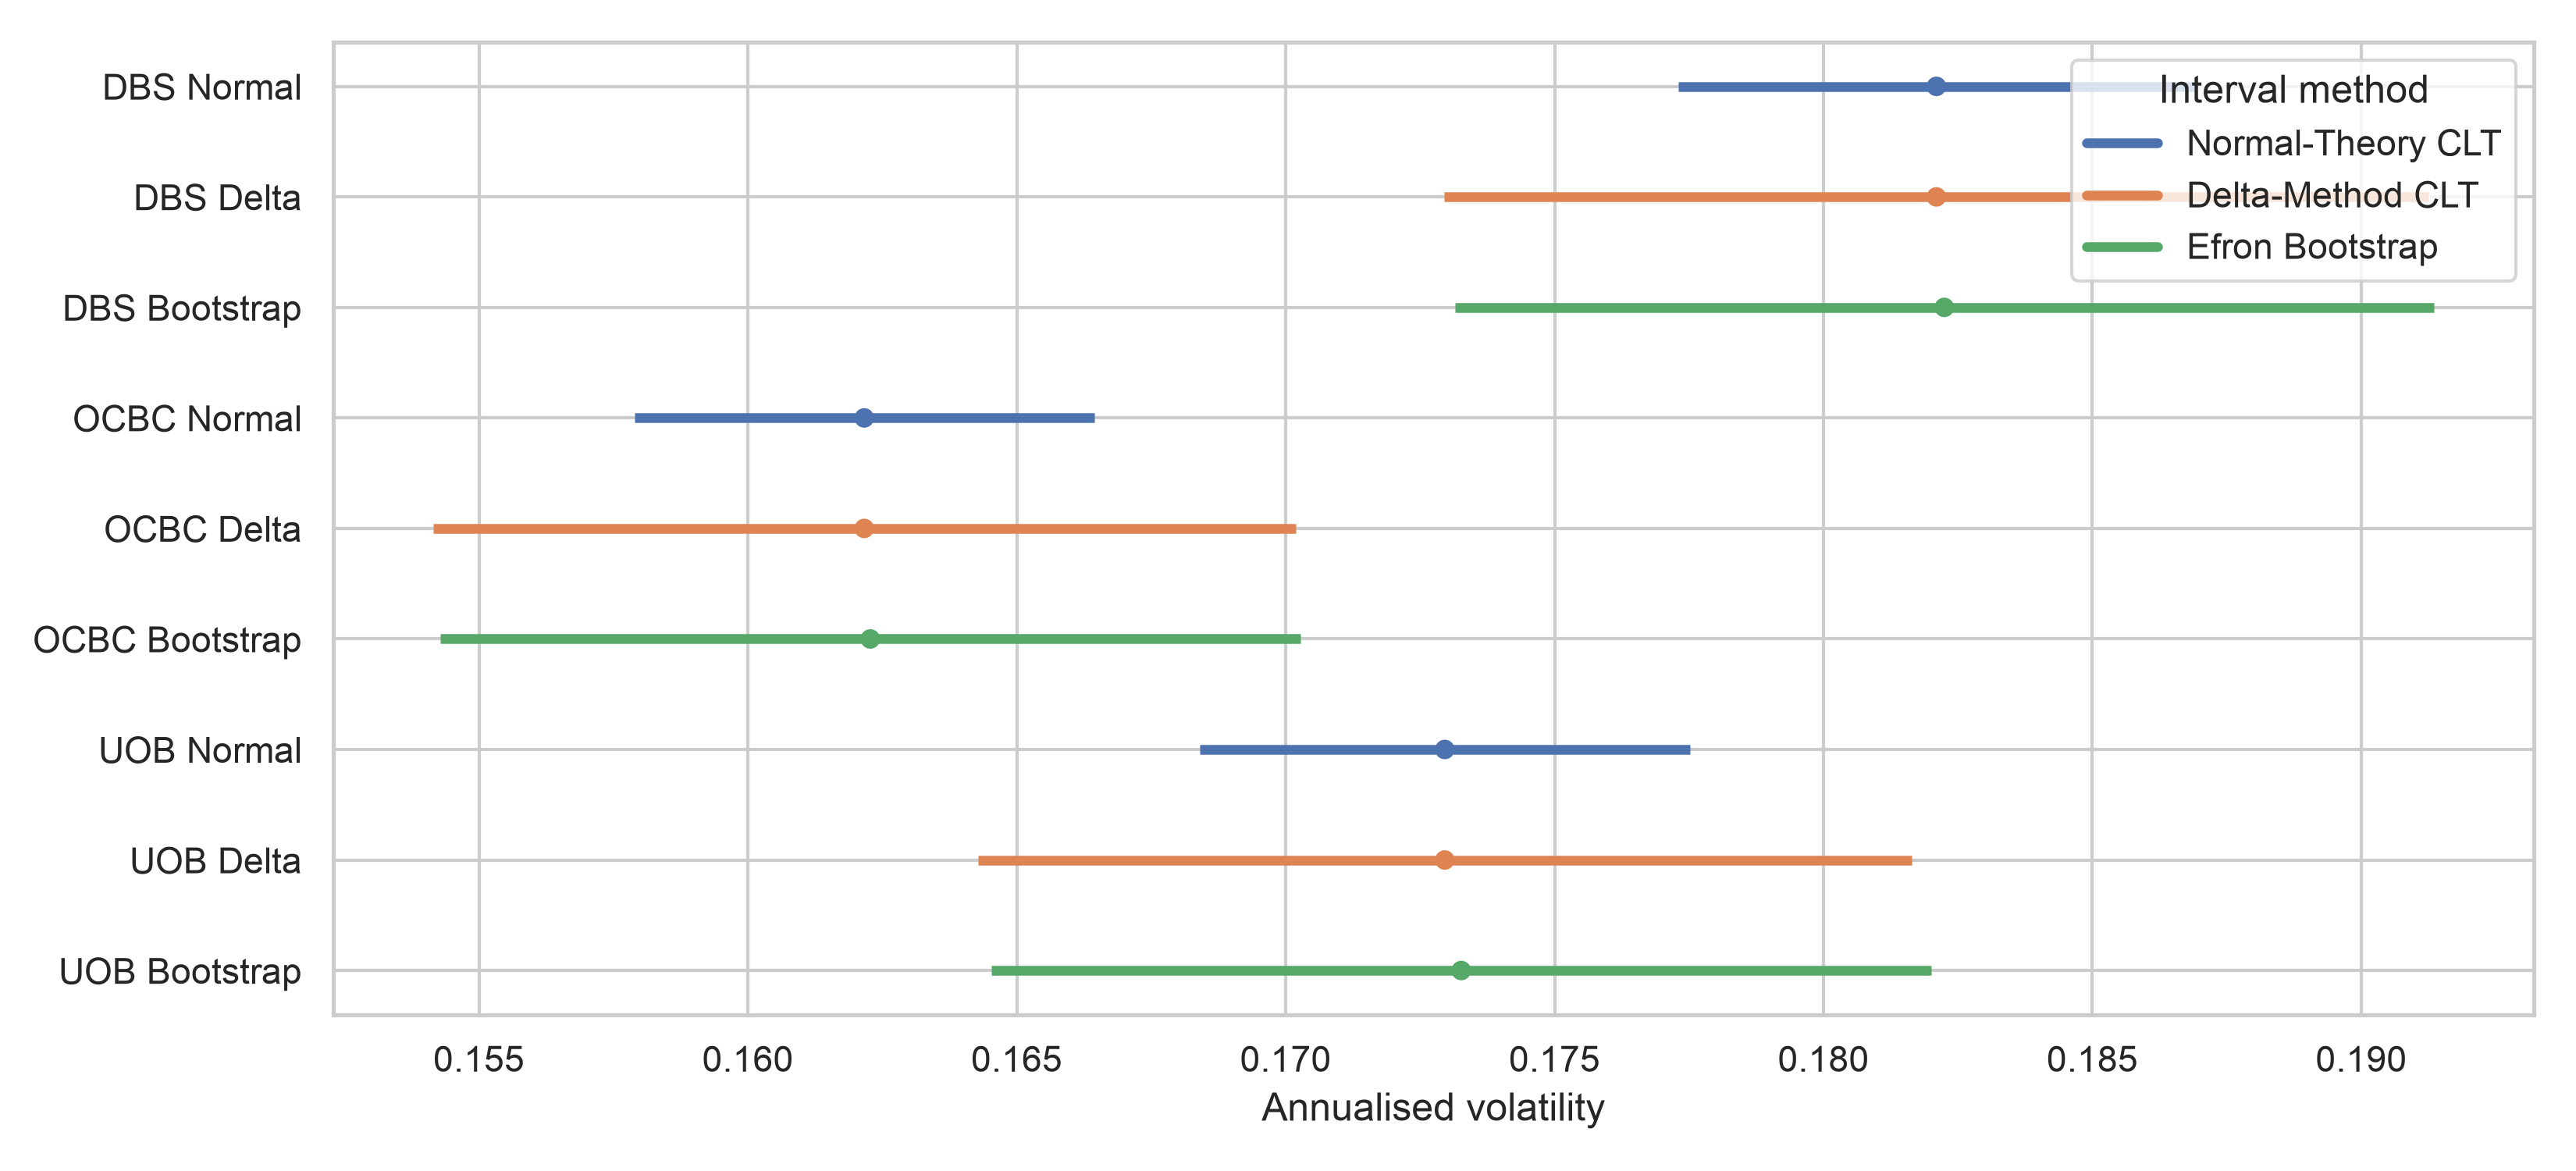

In [5]:
from IPython.display import Image, display
display(Image(filename="outputs/figures/step6_clt_vs_bootstrap_cis.png"))

The interval plot makes the Normal-theory discrepancy and the close agreement of corrected delta and bootstrap volatility uncertainty visible.